In [78]:
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import math


# Dataset

In [ ]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 128

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


In [80]:
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5647059  ... 0.9607844  0.5        0.5       ]
  ...
  [0.5        0.5        0.21568629 ... 0.7960785  0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.62352943 ... 0.9607844  0.5        0.5       ]
  ...
  [0.5        0.5        0.227451   ... 0.85098046 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

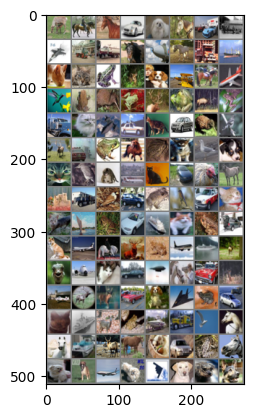

deer  horse horse car   dog   horse car   truck plane truck truck horse plane horse truck ship  cat   cat   frog  deer  dog   plane horse plane bird  frog  bird  frog  deer  frog  deer  frog  truck cat   plane car   cat   car   bird  bird  deer  car   frog  horse frog  dog   bird  dog   cat   bird  cat   plane cat   car   bird  horse cat   truck bird  car   frog  bird  car   cat   cat   ship  frog  car   ship  cat   frog  car   dog   plane horse deer  frog  plane ship  deer  bird  plane cat   car   plane horse car   deer  plane deer  deer  car   dog   plane frog  car   cat   ship  deer  frog  ship  truck bird  horse horse ship  deer  horse dog   car   frog  horse dog   dog   plane dog   plane dog   dog   dog  


In [81]:
def imshow(img):
    img = img / 2 + 0.5
    # normalize: 
    npimg = img.numpy()
    print(npimg)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()
dataiter = iter(train_loader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

# Softmax Model Configuration

In [ ]:
SEED = 42
EPOCHS = 20
LEARNING_RATE = 0.01

torch.manual_seed(SEED)
np.random.seed(SEED)

# Softmax Model

In [83]:
class SoftmaxClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Input: 3 x 32 x 32 = 3072 values
        # Output: 10 logits
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(3 * 32 * 32, num_classes)

    def forward(self, x):
        x = self.flatten(x)  # [B, 3, 32, 32] -> [B, 3072]
        logits = self.fc(x)  # [B, 3072] -> [B, 10]
        return logits

# Define a Loss function and optimizer

In [84]:
import torch.optim as optim

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SoftmaxClassifier(num_classes=10).to(device)

# Explicitly initialize parameters
nn.init.xavier_uniform_(model.fc.weight)
nn.init.zeros_(model.fc.bias)

# Create optimizer for this exact model
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.9
)

# Training & Analysis

## Training

In [86]:
# Count model parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\n========== Model Information ==========")
print(model)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print("\nWeight shape:", tuple(model.fc.weight.shape))
print("Bias shape:", tuple(model.fc.bias.shape))

# Evaluation function
def evaluate(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    avg_loss = total_loss / total_samples
    accuracy = 100.0 * total_correct / total_samples

    return avg_loss, accuracy

# Training loop
history = {
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": []
}

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Reset gradient
        optimizer.zero_grad()

        # Forward pass
        logits = model(images)

        # Compute loss
        loss = criterion(logits, labels)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Statistics
        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    train_loss = running_loss / total_samples
    train_acc = 100.0 * total_correct / total_samples

    # Evaluate on test data after each epoch
    test_loss, test_acc = evaluate(
        model, test_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.5f}"
    )



========== Model Information ==========
SoftmaxClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=3072, out_features=10, bias=True)
)
Total parameters: 30730
Trainable parameters: 30730

Weight shape: (10, 3072)
Bias shape: (10,)
Epoch [01/5] Train Loss: 1.9157 | Test Loss: 1.8157 | Train Acc: 32.91% | Test Acc: 37.45% | LR: 0.00100
Epoch [02/5] Train Loss: 1.7939 | Test Loss: 1.7744 | Train Acc: 38.51% | Test Acc: 38.83% | LR: 0.00100
Epoch [03/5] Train Loss: 1.7596 | Test Loss: 1.7556 | Train Acc: 39.75% | Test Acc: 39.78% | LR: 0.00100
Epoch [04/5] Train Loss: 1.7386 | Test Loss: 1.7439 | Train Acc: 40.71% | Test Acc: 40.04% | LR: 0.00100
Epoch [05/5] Train Loss: 1.7252 | Test Loss: 1.7355 | Train Acc: 41.21% | Test Acc: 40.28% | LR: 0.00100


## Save Model

In [87]:
PATH = './softmax_cifar10.pth'
torch.save(model.state_dict(), PATH)

# Testing

[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.61960787 ... 0.08235294 0.5        0.5       ]
  ...
  [0.5        0.5        0.58431375 ... 0.9215687  0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.43921572 ... 0.09803921 0.5        0.5       ]
  ...
  [0.5        0.5        0.6117647  ... 0.8000001  0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

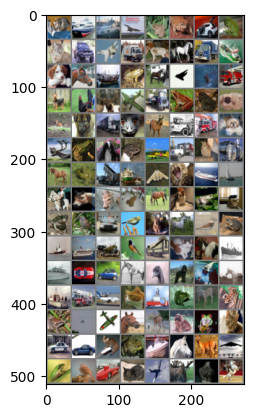

GroundTruth:  cat   ship  ship  plane


In [ ]:
dataiter = iter(test_loader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [89]:
softm = SoftmaxClassifier(num_classes=10)
softm.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [90]:
outputs = softm(images)

In [91]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  frog  truck ship  plane


In [92]:
correct = 0
total = 0

with torch.no_grad():
    for data in test_loader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = softm(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the Softmax Model on the 10000 test images: {100 * correct // total} %')

Accuracy of the Softmax Model on the 10000 test images: 40 %


In [93]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        outputs = softm(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 50.6 %
Accuracy for class: car   is 48.9 %
Accuracy for class: bird  is 26.7 %
Accuracy for class: cat   is 21.7 %
Accuracy for class: deer  is 27.1 %
Accuracy for class: dog   is 32.8 %
Accuracy for class: frog  is 54.1 %
Accuracy for class: horse is 44.0 %
Accuracy for class: ship  is 46.0 %
Accuracy for class: truck is 50.9 %


# Analysis

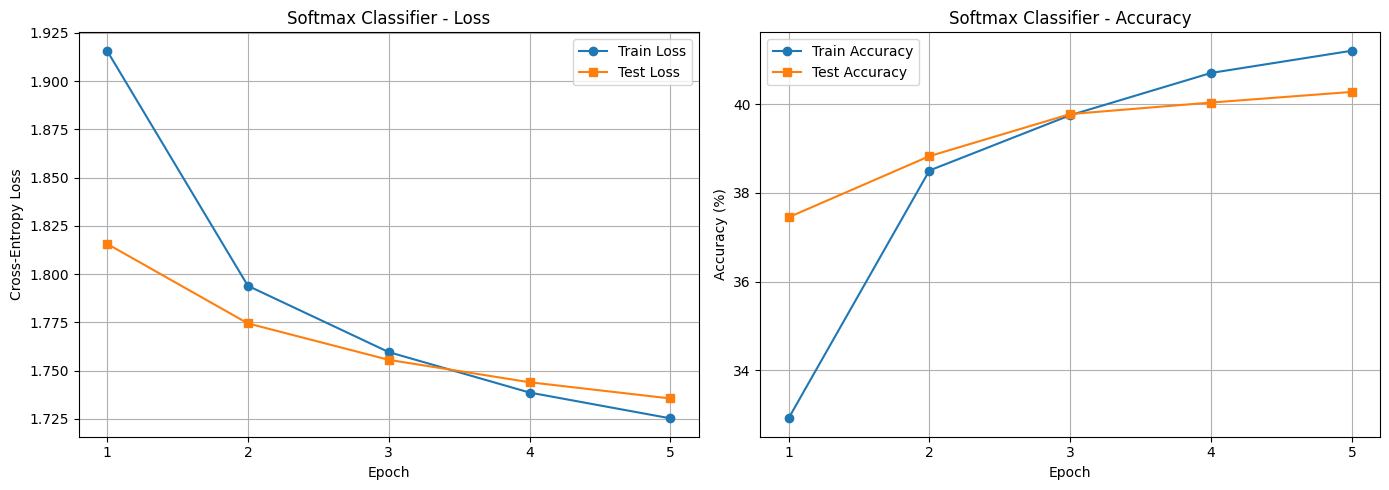

In [94]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(
    epochs_range, history["train_loss"],
    marker="o", label="Train Loss"
)
axes[0].plot(
    epochs_range, history["test_loss"],
    marker="s", label="Test Loss"
)
axes[0].set_title("Softmax Classifier - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(list(epochs_range))
axes[0].grid(True)
axes[0].legend()

# Accuracy curve
axes[1].plot(
    epochs_range, history["train_acc"],
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    epochs_range, history["test_acc"],
    marker="s", label="Test Accuracy"
)
axes[1].set_title("Softmax Classifier - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_xticks(list(epochs_range))
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

# Confusion Matrix

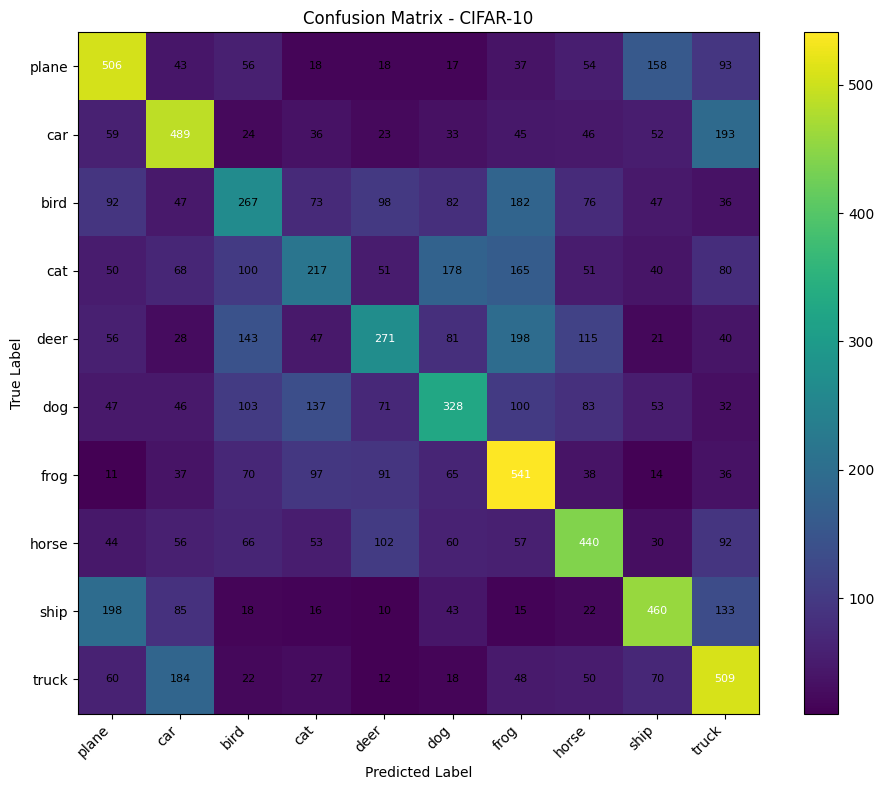

In [95]:
model.eval()

confusion_matrix = torch.zeros(
    10, 10, dtype=torch.int64
)

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        # Rows = true class; columns = predicted class
        indices = labels * 10 + predictions

        counts = torch.bincount(
            indices.cpu(), minlength=100
        ).reshape(10, 10)

        confusion_matrix += counts

cm = confusion_matrix.numpy()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix - CIFAR-10")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

threshold = cm.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# Display Misclassified Images

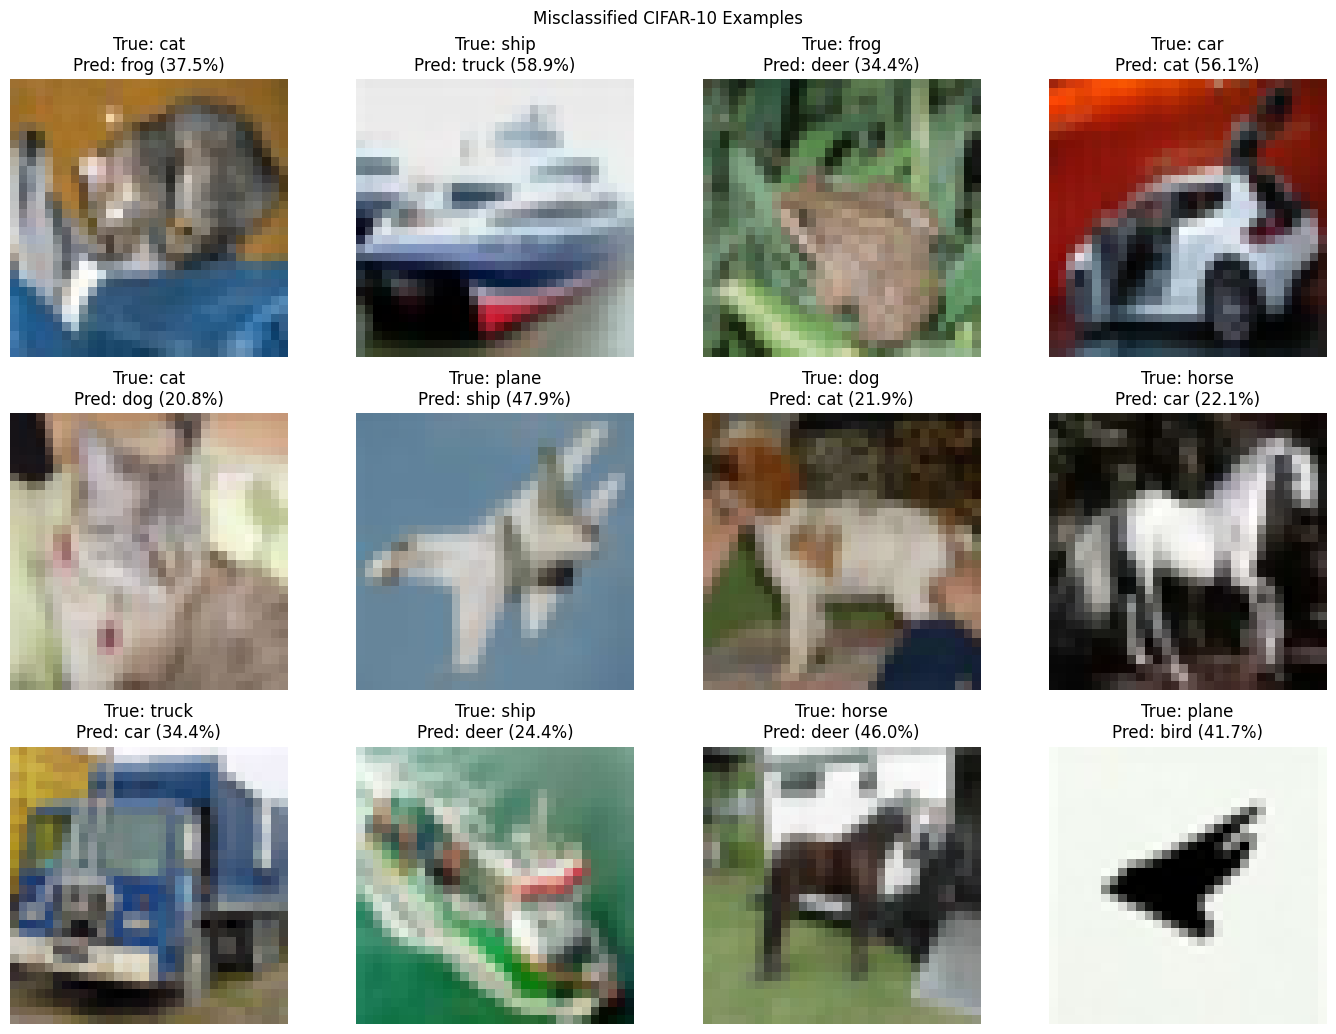


Final results
Train Loss: 1.7252
Test Loss:  1.7355
Train Acc:  41.21%
Test Acc:   40.28%
Number of model parameters: 30,730
Number of test errors: 5972


In [96]:
model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        predictions = logits.argmax(dim=1)
        wrong_indices = (
            predictions != labels
        ).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(
                images[idx].cpu()
            )
            wrong_labels.append(
                labels[idx].item()
            )
            wrong_predictions.append(
                predictions[idx].item()
            )
            wrong_confidences.append(
                probabilities[idx, predictions[idx]].item()
            )

            # Keep the first 12 errors
            if len(wrong_images) >= 12:
                break

        if len(wrong_images) >= 12:
            break

if len(wrong_images) == 0:
    print("No misclassified examples found.")
else:
    n = len(wrong_images)
    cols = 4
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3.5 * rows)
    )
    axes = np.asarray(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")

    for i in range(n):
        # Undo Normalize(mean=0.5, std=0.5)
        image = wrong_images[i] * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image, 0, 1)

        true_name = classes[wrong_labels[i]]
        pred_name = classes[wrong_predictions[i]]
        confidence = wrong_confidences[i] * 100

        axes[i].imshow(image)
        axes[i].set_title(
            f"True: {true_name}\n"
            f"Pred: {pred_name} ({confidence:.1f}%)"
        )

    fig.suptitle("Misclassified CIFAR-10 Examples")
    plt.tight_layout()
    plt.show()

print("\nFinal results")
print(f"Train Loss: {history['train_loss'][-1]:.4f}")
print(f"Test Loss:  {history['test_loss'][-1]:.4f}")
print(f"Train Acc:  {history['train_acc'][-1]:.2f}%")
print(f"Test Acc:   {history['test_acc'][-1]:.2f}%")
print(f"Number of model parameters: {total_params:,}")
print(f"Number of test errors: {int(cm.sum() - np.trace(cm))}")
